# 3D DC inversion with surface and borehole electrodes

Synthetic example: a conductive prism in a resistive half-space is surveyed with two long current dipoles at the
surface, and potential dipoles at the surface and in boreholes.  The voltages are computed with `GridDC` on a
3D finite-volume grid and inverted.

The notebook also writes the data files used by `example_joint.ipynb` and `example_joint_blocky.ipynb`.
The direct solver MUMPS is used; see `example_dc_bicgstab.ipynb` for the same inversion with an iterative solver.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('..'))   # notebook run from the examples directory

from pymmr.finite_volume import calc_padding, GridFV
from pymmr.dc import GridDC
from pymmr.inversion import Inversion, DataERT

## Grid

Cells of 60 m in a core region from −960 to 960 m in $x$ and $y$, and from −960 m to the surface in $z$,
with 10 padding cells of increasing size (`calc_padding`) on the sides and at the bottom.  The region of
interest (`set_roi`) is the part of the grid where the model is inverted and the sensitivity computed:
$|x|, |y| \le 400$ m, $z \ge -960$ m.

In [2]:
x = np.arange(-60.0*16, 60.01*16, 60)
y = np.arange(-60.0*16, 60.01*16, 60)
z = np.arange(-60.0*16, 0.01, 60)

pad = np.cumsum(calc_padding(60.0, 10))

x = np.r_[x[0] - pad[::-1], x, x[-1] + pad]
y = np.r_[y[0] - pad[::-1], y, y[-1] + pad]
z = np.r_[z[0] - pad[::-1], z]

g = GridDC((x, y, z))
g.set_roi([-400, 400, -400, 400, -960, 0])
g.fv.set_solver('mumps')
#g.fv.set_solver('umfpack')

## True model

A conductive prism, 0.1 S/m (10 Ω·m), 400 m × 400 m in plan ($|x|, |y| < 200$ m) and from 80 to 480 m depth,
in a 0.001 S/m (1000 Ω·m) half-space.

In [3]:
sigma = 0.001 + np.zeros((g.nc,))

ix = np.where(np.logical_and(g.fv.xc > -200, g.fv.xc < 200))[0]
iy = np.where(np.logical_and(g.fv.yc > -200, g.fv.yc < 200))[0]
iz = np.where(np.logical_and(g.fv.zc <  -80, g.fv.zc > -480))[0]
sigma[g.fv.ind(ix, iy, iz)] = 0.1

## Survey

Two current dipoles (C1–C2), 1200 m long, centred on the prism: one along $x$, one along $y$.  The
potential dipoles (P1–P2) are measured for both sources:

- **surface:** 26 × 26 electrodes from −400 to 400 m (32 m spacing); dipoles along $x$ and along $y$, between
  adjacent electrodes and between electrodes two positions apart (2548 dipoles);
- **downhole:** four boreholes at $(\pm300, \pm300)$ m, 10 electrodes from 600 to 20 m depth, dipoles of one and
  two spacings (68 dipoles);
- **long horizontal dipoles:** 600 m long, at the 10 borehole depths, along $x$ and along $y$ through the
  centre (20 dipoles).

The survey is given to `set_survey_ert` as one row per measurement (coordinates of C1, C2, P1 and P2).  A few rows
are then removed and some are swapped, to check that pymmr handles measurements in any order and sources with
different numbers of dipoles.

In [4]:
c1c2 = np.array([[-600.0, 0.0, 0.0, 600.0, 0.0, 0.0],
                 [0.0, -600.0, 0.0, 0.0, 600.0, 0.0]])
X = np.linspace(-400, 400, 26)
Y = np.linspace(-400, 400, 26)
z_bh = np.linspace(-600, -20, 10)

p1p2 = []
for y in Y:
    for nx in range(len(X)-1):
        p1p2.append((X[nx], y, 0.0, X[nx+1], y, 0.0))
    for nx in range(len(X)-2):
        p1p2.append((X[nx], y, 0.0, X[nx+2], y, 0.0))
for x in X:
    for ny in range(len(Y)-1):
        p1p2.append((x, Y[ny], 0.0, x, Y[ny+1], 0.0))
    for ny in range(len(Y)-2):
        p1p2.append((x, Y[ny], 0.0, x, Y[ny+2], 0.0))

p1p2_surf = np.array(p1p2)

X = (-300.0, 300.0)
# downhole
for x in X:
    for y in X:
        for nz in range(len(z_bh)-1):
            p1p2.append((x, y, z_bh[nz], x, y, z_bh[nz+1]))
        for nz in range(len(z_bh)-2):
            p1p2.append((x, y, z_bh[nz], x, y, z_bh[nz+2]))
# crosshole
for nz in range(len(z_bh)):
    p1p2.append((X[0], 0.0, z_bh[nz], X[1], 0.0, z_bh[nz]))
for nz in range(len(z_bh)):
    p1p2.append((0.0, X[0], z_bh[nz], 0.0, X[1], z_bh[nz]))

p1p2 = np.array(p1p2)

tmp = np.kron(c1c2, np.ones((p1p2.shape[0], 1)))
tmp_surf = np.kron(c1c2, np.ones((p1p2_surf.shape[0], 1)))
p1p2 = np.kron(np.ones((c1c2.shape[0], 1)), p1p2)
p1p2_surf = np.kron(np.ones((c1c2.shape[0], 1)), p1p2_surf)
c1c2 = tmp
c1c2_surf = tmp_surf

# on enlève quelques points
mask = np.ones((c1c2.shape[0],), dtype=bool)
mask[50:60] = False
mask[2000:2100] = False
mask[-30:] = False
c1c2 = c1c2[mask, :]
p1p2 = p1p2[mask, :]

# on change l'ordre
ind = np.arange(c1c2.shape[0])
ind[9] = 2220
ind[2220] = 9
ind[1802] = 14
ind[14] = 1802
c1c2 = c1c2[ind, :]
p1p2 = p1p2[ind, :]

## Synthetic data

`fwd_mod` returns the voltages in mV (for the current `cs` = 1 A given to `set_survey_ert`); with
`calc_J=True` it also returns the current density.  The data are put in a `DataERT` with errors (`wt`) of 1 %,
and written to `data_dc.dat`.  The data of the surface dipoles only are computed again and written to
`data_dc_surf.dat`; the joint inversion notebooks use this file.

In [5]:
g.set_survey_ert(c1c2, p1p2, 1.0)
data, J = g.fwd_mod(sigma, calc_J=True)

# g.save_current_density(J, 'example_dc_J')

data_ert = DataERT(c1c2=c1c2, p1p2=p1p2, data=data, wt=np.ones((data.shape[0],)), cs=1.0, date=None)

filename = "data_dc.dat"
header = "c1_x c1_y c1_z c2_x c2_y c2_z p1_x p1_y p1_z p2_x p2_y p2_z V cs"
np.savetxt(filename, np.c_[c1c2, p1p2, data, g.cs], header=header, fmt="%g")

g.set_survey_ert(c1c2_surf, p1p2_surf, 1.0)
data_surf = g.fwd_mod(sigma)

filename = "data_dc_surf.dat"
header = "c1_x c1_y c1_z c2_x c2_y c2_z p1_x p1_y p1_z p2_x p2_y p2_z V cs"
np.savetxt(filename, np.c_[c1c2_surf, p1p2_surf, data_surf, g.cs], header=header, fmt="%g")

## Inversion

Gauss-Newton inversion of the voltages (all electrodes) for $\ln\sigma$, with the default smoothness
regularization:

- starting and reference model: the 1000 Ω·m half-space;
- smoothness weights `alx`, `aly`, `alz` = 0.5;
- $\beta$ from 1, divided by 2 (`beta_cooling`) at each iteration down to `beta_min` = 0.01;
- 5 iterations;
- distance weighting of the model (`model_weighting = 'distance'`, the default) with exponent `beta_dw` = 1,
  to counteract the decrease of sensitivity away from the electrodes;
- only the cells in the region of interest are inverted (`m_active`).

With `show_plots = True`, a panel of diagnostics is displayed at each iteration: the step, the model and data
weights, the observed and computed data and their difference, the RMS misfit and $\beta$.  The models of all the
iterations are written to `example_dc.vtr` on the region of interest, for visualization with ParaView.  The true model is written to `m_true.vtr`, on the same grid.


Inversion
    Grid: 52 x 52 x 26 voxels
      X min: -4.284321e+03	X max: 4.284321e+03
      Y min: -4.284321e+03	Y max: 4.284321e+03
      Z min: -4.284321e+03	Z max: 0.000000e+00
    Region of interest:
      X min: -4.000000e+02	X max: 4.000000e+02
      Y min: -4.000000e+02	Y max: 4.000000e+02
      Z min: -9.600000e+02	Z max: 0.000000e+00
    Number of parameters to estimate: 3136
    Number of ERT data: 5132
    Algorithm: Gauss-Newton
    Maximum number of iterations: 5
    Working variable: log_conductivity
    Type of smoothing: smooth
      Smoothing factor along x: 0.5
      Smoothing factor along y: 0.5
      Smoothing factor along z: 0.5
      Smallness factor: 0.01
    Regularization variable: model
    Regularization β: 1
      Cooling factor: 2
      Min value: 0.01
    Data weighting: variance
      error floor 𝜖: 0.1
    Model weighting: distance
      Distance weighting β: 1
    cglscd: preconditioner regularization, tol 1e-09, max_it auto
    Conductivity bounds: 2

  ------------------------------------------------------------
  *** Iteration no 1 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 9.04889, misfit: 0.322481, smy: 0
    Computing perturbation with cglscd ... 

    Factorizing regularization matrix ... 

done.


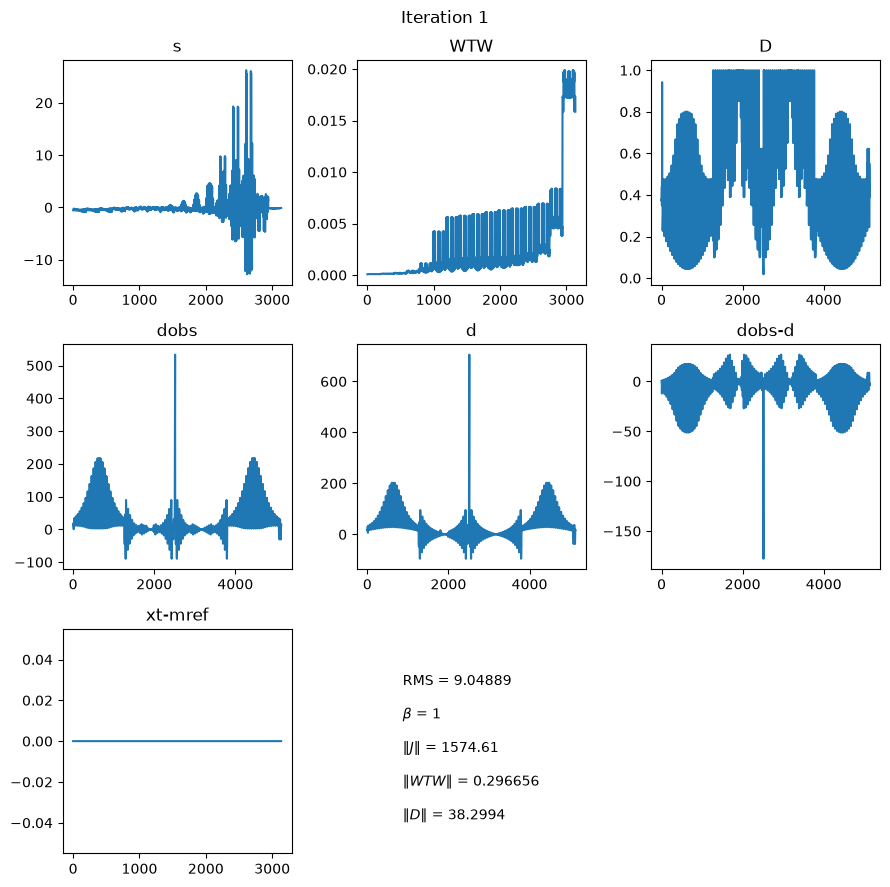

<Figure size 640x480 with 0 Axes>

done.
      err = 8.850196e-10, iter = 2710
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
  *** Iteration no 2 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 5.49218, misfit: 0.202489, smy: 2291.55
    Computing perturbation with cglscd ... 

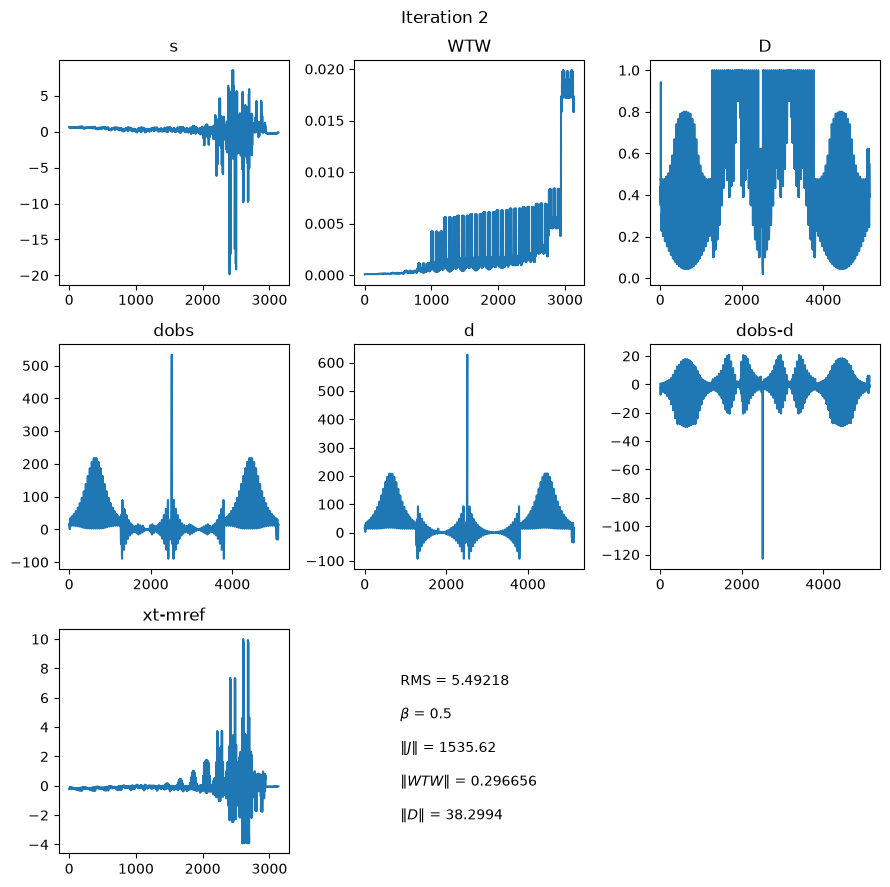

<Figure size 640x480 with 0 Axes>

done.
      err = 7.210157e-10, iter = 3897
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
  *** Iteration no 3 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 3.26592, misfit: 0.12059, smy: 1359.67
    Computing perturbation with cglscd ... 

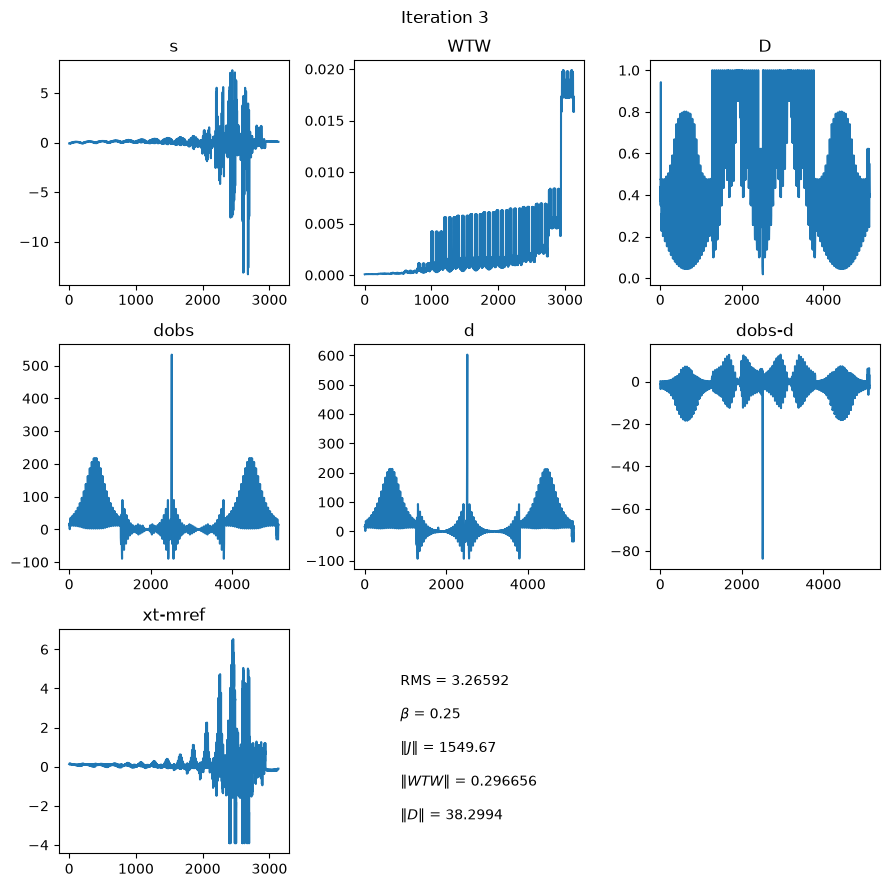

<Figure size 640x480 with 0 Axes>

done.
      err = 8.924394e-10, iter = 5384
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
  *** Iteration no 4 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 3.20215, misfit: 0.121093, smy: 712.655
    Computing perturbation with cglscd ... 

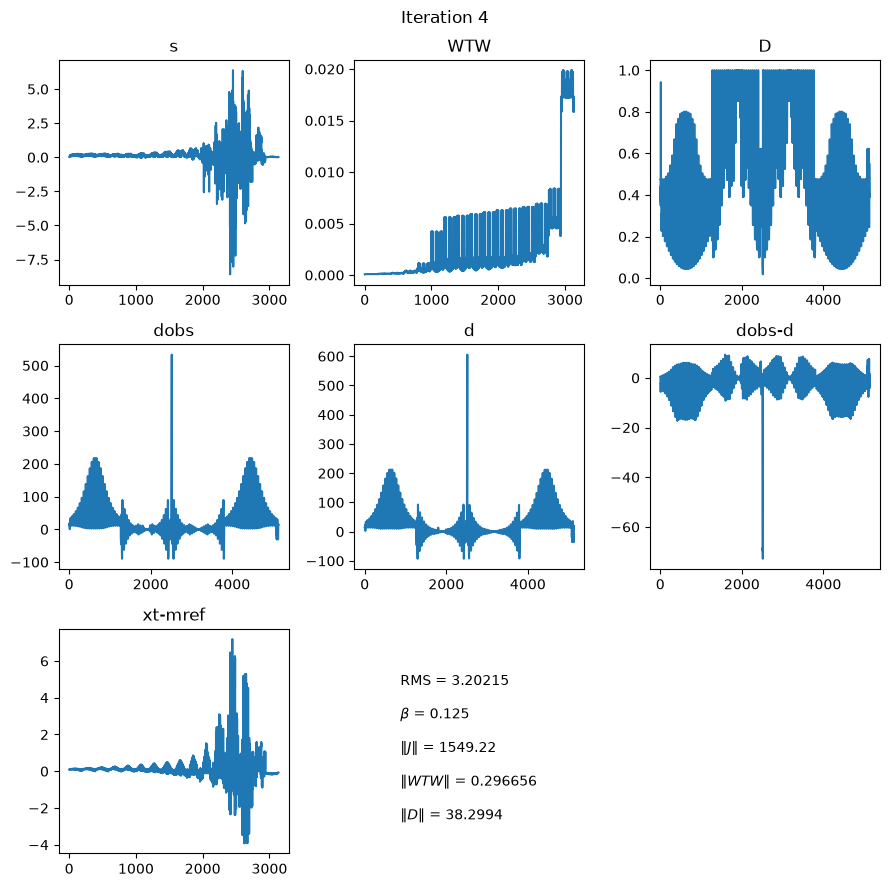

<Figure size 640x480 with 0 Axes>

done.
      err = 8.089186e-10, iter = 7289
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
  *** Iteration no 5 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 2.19961, misfit: 0.0763144, smy: 1926.94
    Computing perturbation with cglscd ... 

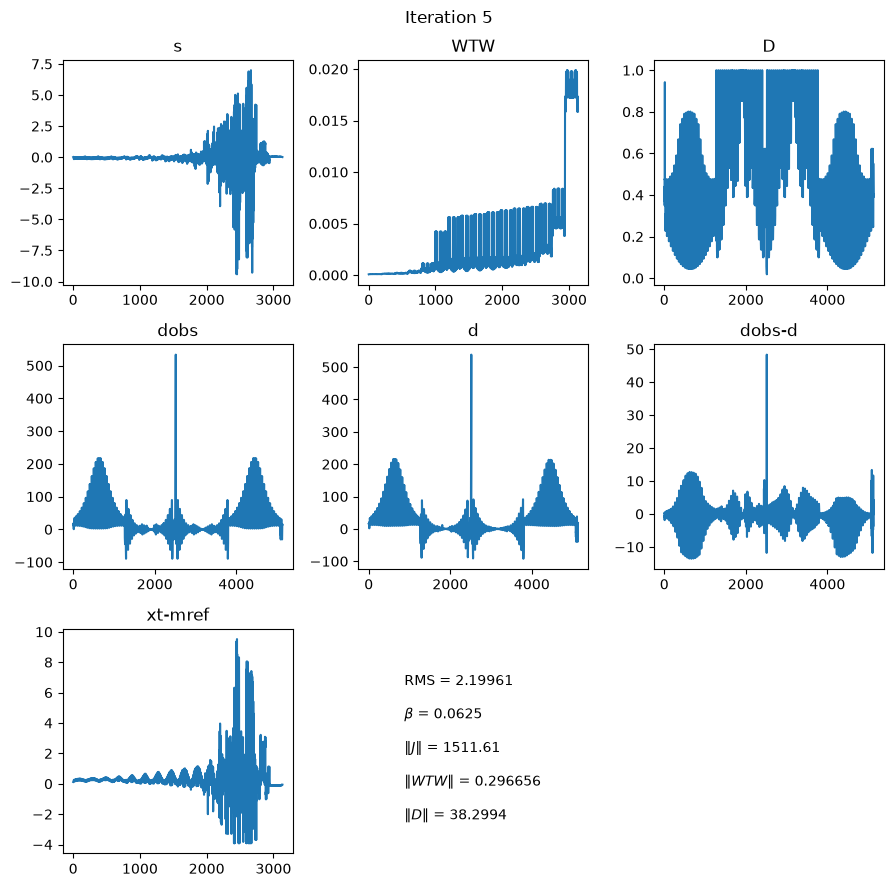

<Figure size 640x480 with 0 Axes>

done.
      err = 9.871435e-10, iter = 9687
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
End of inversion.


In [6]:
inv = Inversion()
inv.max_it = 5
inv.alx = 0.5
inv.aly = 0.5
inv.alz = 0.5
inv.beta = 1
inv.beta_min = 0.01
inv.beta_dw = 1.0
#inv.smooth_type = 'blocky'
inv.show_plots = True

g.verbose = False
m0 = 0.001 + np.zeros((g.nc,))
m_ref = m0
results = inv.run(g, m0, m_ref, data_ert=data_ert, m_active=g.ind_roi)

sigma_inv, data_inv, rms, misfit, smy = results
g.verbose = True

x, y, z = g.get_roi_nodes()
g2 = GridFV((x, y, z))

fields = {}

for n, sigma in enumerate(sigma_inv):
    name = 'dc - iteration {0:d}'.format(n+1)
    fields[name] = sigma

g2.toVTK(fields, 'example_dc')

sigma = 0.001 + np.zeros((g2.nc,))
ix = np.where(np.logical_and(g2.xc > -200, g2.xc < 200))[0]
iy = np.where(np.logical_and(g2.yc > -200, g2.yc < 200))[0]
iz = np.where(np.logical_and(g2.zc < -80, g2.zc > -480))[0]
sigma[g2.ind(ix, iy, iz)] = 0.1
g2.toVTK({'Conductivity': sigma}, 'm_true')

## Misfit

Data misfit (RMSE weighted by the data errors) at each iteration.

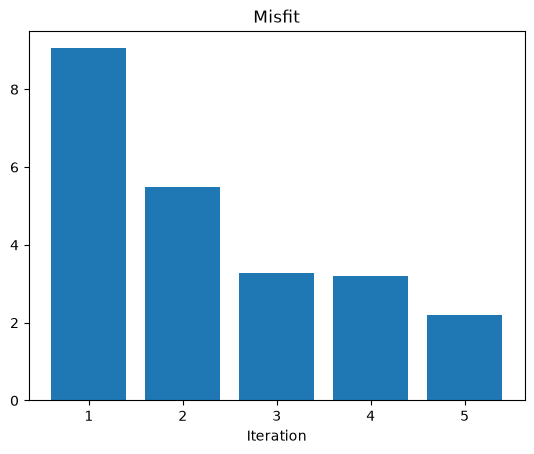

In [7]:
plt.figure()
plt.bar(np.arange(1, 1+len(rms)), rms)
plt.xlabel('Iteration')
plt.title('Misfit')
plt.show()